# Example of interface usage — Read the orbit

Read the BPM positions and plot the average orbit. This example uses the tutorial beamline, with positions in mm. For another machine, create its interface instead and use its BPM names.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from tutorial_support import Beamline

interface = Beamline(nsamples=32)
print('BPMs:', interface.get_bpms()['names'])

BPMs: ['BPM1', 'BPM2', 'BPM3', 'BPM4', 'BPM5']


## Read one measurement

A snapshot keeps the readings from one acquisition. `get_bpms()` gives the individual shots: rows are shots, columns are BPMs. `get_orbit()` averages those same shots. Choose BPMs by name; use the returned `names` for the plot order.

In [2]:
bpms = ['BPM1', 'BPM3', 'BPM5']
snapshot = interface.get_state()
shots = snapshot.get_bpms(bpms)
orbit = snapshot.get_orbit(bpms)
print('Shots × BPMs:', shots['x'].shape)
for name, x, y in zip(orbit['names'], orbit['x'], orbit['y']):
    print(f'{name}: x = {x:.4f} mm, y = {y:.4f} mm')

Shots × BPMs: (32, 3)
BPM1: x = 0.0382 mm, y = -0.0290 mm
BPM3: x = 0.1165 mm, y = -0.0863 mm
BPM5: x = 0.1176 mm, y = -0.0561 mm


## Plot the average and its uncertainty

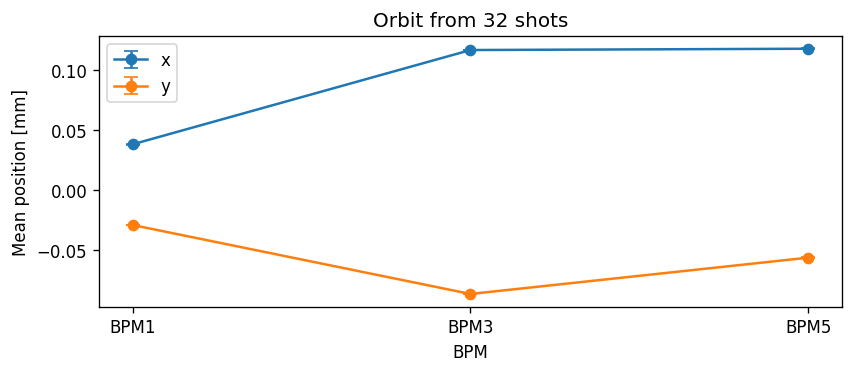

In [3]:
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
for plane in ('x', 'y'):
    u_mean = orbit['std' + plane] / np.sqrt(orbit['nshots'])
    ax.errorbar(orbit['names'], orbit[plane], yerr=u_mean, fmt='o-', capsize=4, label=plane)
ax.set(xlabel='BPM', ylabel='Mean position [mm]', title='Orbit from 32 shots')
ax.legend()
plt.show()

These are beam positions relative to each BPM zero. They are not beam sizes. To measure a change, subtract an earlier orbit, as in [Dispersion Measurement](00a_DispersionMeasurement.ipynb).